# 1A-5. 레짐 점검 (체크포인트 A)

**레짐** = 데이터가 만들어지는 규칙이 같은 기간. 같은 레짐 안에서는 신고율의 평균 수준이 유지되고, 레짐이 바뀌면 수준이 계단처럼 달라진다.

**이 노트북이 답하려는 질문**
1. 신고율(대여 만 건당 고장신고)의 수준이 언제 바뀌었나?
2. 그 변화는 모든 부품에서 같이 일어났나, 특정 부품에 몰렸나?
3. 테스트 구간(2025 ~ 2026 상반기)은 검증 구간(2024)·학습 구간(2020~2023)과 같은 레짐인가?

**왜 중요한가**: 모형은 과거(학습 구간)의 수준을 배운다. 테스트 구간의 수준이 다르면 날씨·요일 효과를 잘 맞혀도 예측이 통째로 높거나 낮게 나온다.

**지키는 규칙**: 테스트 구간(2025-01-01 이후)은 **월별 수준만** 본다. 요일·날씨 패턴 분석에는 쓰지 않는다(그걸 보고 변수를 고르면 성능이 실제보다 좋아 보인다).

입력: `data/processed/daily_master_v2.parquet` (만든 곳: `1A_Build_master.ipynb`) · 결과 표·그림: `output/tables/regime_*.csv`, `output/figures/regime_*.png`

In [1]:
import numpy as np, pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "AppleGothic"      # 맥 한글 글꼴
plt.rcParams["axes.unicode_minus"] = False       # 음수 부호 깨짐 방지
pd.set_option("display.width", 200)
ROOT = Path("..")                                # 프로젝트 폴더(이 노트북은 notebooks/ 안에 있다)

m = pd.read_parquet(ROOT / "data/processed/daily_master_v2.parquet")
m = m[~m.no_service]                             # 운영이 멈춘 날 3일(2017-07-06, 2019-09-07, 2022-08-09)은 신고율을 계산할 수 없다 → 제외

# 부품별 열 이름 → 그림·표에 쓸 한글 이름. 부품별은 행 수(fail_*), 전체는 신고 건수(total_faults)
PARTS = {"fail_tire": "타이어", "fail_chain": "체인", "fail_saddle": "안장", "fail_pedal": "페달",
         "fail_terminal": "단말기", "fail_etc": "기타", "total_faults": "전체(신고 건수)"}

## 1. 월별 신고율 추이

하루 단위는 요일·날씨 때문에 들쭉날쭉하므로 한 달씩 묶어 본다. 신고율은 "그 달 신고 합계 ÷ 그 달 대여 합계 × 10,000"이다(일별 비율의 평균이 아니라 합계끼리 나눈다. 대여가 적은 날의 튀는 값에 휘둘리지 않게).

분모를 이용시간으로 바꾼 신고율도 같이 그린다. 두 선이 같은 모양이면 "어떤 노출을 쓰느냐"와 상관없이 수준 변화가 실제로 있다는 뜻이다.

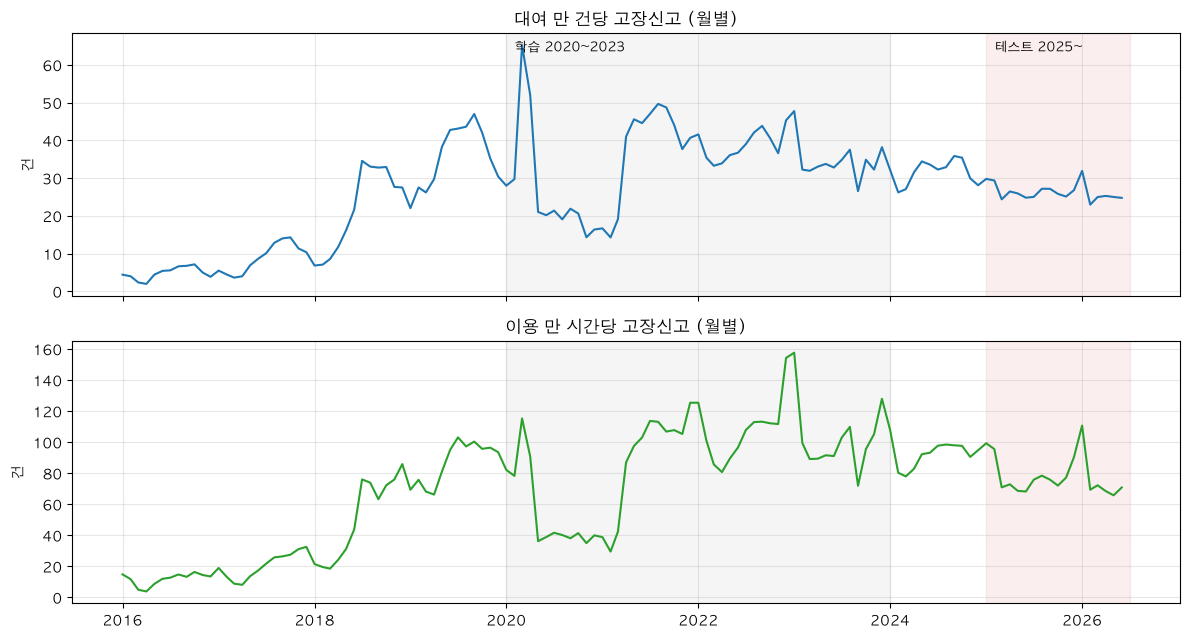

In [2]:
mon = m.groupby(m.date.dt.to_period("M"))[list(PARTS) + ["rentals", "use_hours"]].sum()
mon["rate"] = mon.total_faults / mon.rentals * 1e4          # 대여 만 건당 신고
mon["rate_h"] = mon.total_faults / mon.use_hours * 1e4      # 이용 만 시간당 신고
mon.to_csv(ROOT / "output/tables/regime_monthly.csv")

fig, ax = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
x = mon.index.to_timestamp()
ax[0].plot(x, mon.rate, color="tab:blue")
ax[0].set_title("대여 만 건당 고장신고 (월별)"); ax[0].set_ylabel("건")
ax[1].plot(x, mon.rate_h, color="tab:green")
ax[1].set_title("이용 만 시간당 고장신고 (월별)"); ax[1].set_ylabel("건")
for a in ax:
    a.axvspan(pd.Timestamp("2020-01-01"), pd.Timestamp("2024-01-01"), color="gray", alpha=0.08)      # 학습 구간
    a.axvspan(pd.Timestamp("2025-01-01"), pd.Timestamp("2026-07-01"), color="tab:red", alpha=0.08)   # 테스트 구간
    a.grid(alpha=0.3)
ax[0].text(pd.Timestamp("2020-02-01"), ax[0].get_ylim()[1] * 0.93, "학습 2020~2023", fontsize=9)
ax[0].text(pd.Timestamp("2025-02-01"), ax[0].get_ylim()[1] * 0.93, "테스트 2025~", fontsize=9)
plt.tight_layout(); plt.savefig(ROOT / "output/figures/regime_monthly_rate.png", dpi=200, bbox_inches="tight"); plt.show()

## 2. 계절을 걷어 낸 수준: 최근 12개월 신고율

신고율은 계절을 탄다(여름에 높다). 수준이 바뀐 시점을 보려면 계절을 걷어 내야 한다.
"그 달까지 최근 12개월 신고 합계 ÷ 최근 12개월 대여 합계"는 언제나 사계절이 한 번씩 들어 있어 계절 영향이 상쇄된다.
단, 12개월 평균이라 실제 변화보다 늦게, 완만하게 움직인다.

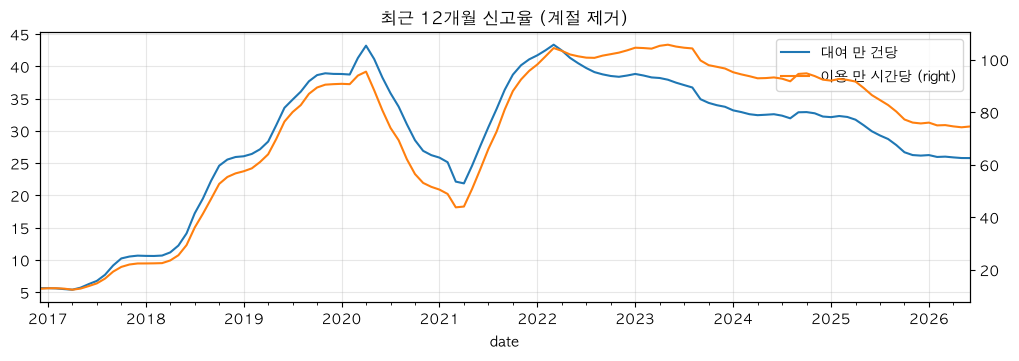

date,2019-06,2019-12,2020-06,2020-12,2021-06,2021-12,2022-06,2022-12,2023-06,2023-12,2024-06,2024-12,2025-06,2025-12,2026-06
대여 만 건당,33.6,38.8,38.3,26.3,27.6,41.1,40.5,38.6,37.5,33.7,32.6,32.2,30.0,26.2,25.8
이용 만 시간당,76.5,90.7,80.8,51.6,58.3,95.8,101.3,103.6,105.0,96.7,93.3,92.4,86.6,75.8,74.6


In [3]:
roll = mon[["total_faults", "rentals", "use_hours"]].rolling(12).sum()
r12 = pd.DataFrame({"대여 만 건당": roll.total_faults / roll.rentals * 1e4,
                    "이용 만 시간당": roll.total_faults / roll.use_hours * 1e4}).dropna()
ax = r12.plot(figsize=(12, 3.5), secondary_y="이용 만 시간당", title="최근 12개월 신고율 (계절 제거)")
ax.grid(alpha=0.3)
plt.savefig(ROOT / "output/figures/regime_rolling12.png", dpi=200, bbox_inches="tight"); plt.show()
r12[r12.index.month.isin([6, 12])].loc["2019":].round(1).T          # 반기 말 시점의 값만 표로

## 3. 같은 달끼리 비교 (전년 같은 달 대비)

계절을 걷어 내는 또 하나의 방법. 2025년 3월은 2024년 3월과, 2025년 4월은 2024년 4월과 비교한다.
1보다 작으면 작년 같은 달보다 신고율이 낮다는 뜻이다. 비율이 특정 달부터 계단처럼 바뀌면 그 달 근처가 레짐이 바뀐 시점이다.

In [4]:
yoy = (mon.rate / mon.rate.shift(12)).rename("전년 같은 달 대비 신고율")
tab = yoy.loc["2020":].to_frame().assign(year=lambda t: t.index.year, month=lambda t: t.index.month) \
         .pivot(index="year", columns="month", values="전년 같은 달 대비 신고율")
tab.to_csv(ROOT / "output/tables/regime_yoy.csv")
tab.round(2)

month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2020,1.27,1.08,2.49,1.75,0.55,0.47,0.50,0.44,0.47,0.49,0.41,0.54
2021,0.60,0.48,0.29,0.79,2.17,2.21,2.20,2.61,2.23,2.14,2.63,2.49
2022,2.49,2.48,1.74,0.83,0.79,0.82,0.83,0.85,0.90,0.92,0.97,1.11
2023,1.15,0.91,0.96,0.97,0.94,0.89,0.89,0.89,0.61,0.86,0.88,0.84
2024,0.67,0.81,0.85,0.95,1.02,1.02,0.93,0.88,1.35,1.02,0.93,0.74
2025,0.93,1.12,0.90,0.84,0.75,0.74,0.78,0.83,0.76,0.73,0.84,0.95
2026,1.07,0.78,1.02,0.96,0.96,1.00,NaN,NaN,NaN,NaN,NaN,NaN


## 4. 구조변화 시점을 알고리즘으로 찾기

눈으로 본 시점이 맞는지 `ruptures`(구조변화 탐지 라이브러리)로 확인한다.
방법: 월별 신고율을 "구간마다 평균이 다른 계단"으로 가장 잘 나누는 지점을 찾는다(Binseg, 구간 최소 6개월).
계절 때문에 생기는 오르내림을 변화로 착각하지 않도록, **전년 같은 달과의 차이**(계절이 빠진 값)에도 같은 방법을 적용해 비교한다.
변화 지점을 몇 개로 볼지는 알고리즘이 정해 주지 않는다. 1·2·3개일 때를 각각 보고, 그림에서 납득되는 개수를 사람이 고른다.

In [5]:
import ruptures as rpt

def breaks(series, label):
    """series를 평균이 다른 구간으로 나눌 때의 경계 달을 1·2·3개 경우로 출력한다"""
    algo = rpt.Binseg(model="l2", min_size=6).fit(series.to_numpy())
    for n in (1, 2, 3):
        bk = algo.predict(n_bkps=n)[:-1]                      # 마지막 값은 '끝 지점'이라 뺀다
        print(f"{label} | 변화 {n}개:", [str(series.index[b]) for b in bk])

breaks(mon.loc["2020-01":, "rate"], "월별 신고율(2020~)          ")
breaks((mon.rate - mon.rate.shift(12)).loc["2020-01":].dropna(), "전년 같은 달과의 차이(2020~)")

월별 신고율(2020~)           | 변화 1개: ['2021-04']
월별 신고율(2020~)           | 변화 2개: ['2021-04', '2023-05']
월별 신고율(2020~)           | 변화 3개: ['2021-04', '2023-05', '2025-01']
전년 같은 달과의 차이(2020~) | 변화 1개: ['2021-04']
전년 같은 달과의 차이(2020~) | 변화 2개: ['2021-04', '2022-02']
전년 같은 달과의 차이(2020~) | 변화 3개: ['2021-04', '2022-02', '2023-05']


## 5. 부품별: 변화가 어디에 몰렸나

연도별·부품별 "대여 만 건당 신고"를 구하고, 바로 앞 해와의 비율을 본다.
2026년은 상반기뿐이라 연간 값끼리 비교하면 계절 때문에 왜곡된다 → **상반기(1~6월)끼리만** 따로 비교한다.

읽는 법(런북 02의 해석 가이드)

| 관찰 | 가능한 원인 |
|---|---|
| 모든 부품이 비슷한 비율로 변함 | 신고 경로·집계 방식 변화, 이용자 구성 변화 |
| 체인에 집중 | 체인가드 설치 효과 |
| 타이어·안장에 집중 | 부품 교체, 정비 강화 |

In [6]:
def part_rate(df):
    """연도별·부품별 대여 만 건당 신고"""
    g = df.groupby("year")
    return (g[list(PARTS)].sum().div(g.rentals.sum(), axis=0) * 1e4).rename(columns=PARTS)

by_year = part_rate(m[m.year >= 2019])
by_year.to_csv(ROOT / "output/tables/regime_part_by_year.csv")
print("연도별 대여 만 건당 신고(2026년은 상반기만)")
display(by_year.round(2))
print("앞 해 대비 비율(1.00 = 변화 없음)")
display((by_year / by_year.shift(1)).loc[2020:2025].round(2))

연도별 대여 만 건당 신고(2026년은 상반기만)


,타이어,체인,안장,페달,단말기,기타,전체(신고 건수)
year,,,,,,,
2019,8.32,9.12,4.67,2.96,11.09,6.60,38.84
2020,3.64,5.54,3.44,2.17,7.30,6.92,26.25
2021,8.73,9.97,8.90,4.30,2.24,13.27,41.09
2022,8.16,8.09,8.03,4.09,2.17,13.58,38.59
2023,7.35,7.34,7.06,3.96,1.76,11.02,33.74
2024,6.72,8.60,5.59,4.50,1.59,9.91,32.23
2025,5.91,5.52,4.42,3.38,1.45,9.53,26.18
2026,4.95,5.68,4.30,2.58,1.47,10.28,25.40


앞 해 대비 비율(1.00 = 변화 없음)


,타이어,체인,안장,페달,단말기,기타,전체(신고 건수)
year,,,,,,,
2020,0.44,0.61,0.74,0.73,0.66,1.05,0.68
2021,2.40,1.80,2.59,1.98,0.31,1.92,1.57
2022,0.93,0.81,0.90,0.95,0.97,1.02,0.94
2023,0.90,0.91,0.88,0.97,0.81,0.81,0.87
2024,0.91,1.17,0.79,1.14,0.90,0.90,0.96
2025,0.88,0.64,0.79,0.75,0.91,0.96,0.81


In [7]:
h1 = part_rate(m[(m.year >= 2021) & (m.month <= 6)])            # 상반기끼리 비교(2026년 포함)
h1.to_csv(ROOT / "output/tables/regime_part_h1.csv")
print("상반기(1~6월)만: 대여 만 건당 신고")
display(h1.round(2))
print("앞 해 상반기 대비 비율")
display((h1 / h1.shift(1)).dropna().round(2))

상반기(1~6월)만: 대여 만 건당 신고


,타이어,체인,안장,페달,단말기,기타,전체(신고 건수)
year,,,,,,,
2021,5.87,9.43,7.98,3.68,2.17,11.80,35.53
2022,6.40,7.48,7.75,3.36,2.16,13.58,35.75
2023,6.54,7.40,7.35,3.42,1.89,12.06,33.92
2024,5.28,8.60,6.31,3.79,1.50,10.23,31.52
2025,5.04,5.81,4.53,3.27,1.47,10.11,26.20
2026,4.95,5.68,4.30,2.58,1.47,10.28,25.40


앞 해 상반기 대비 비율


,타이어,체인,안장,페달,단말기,기타,전체(신고 건수)
year,,,,,,,
2022,1.09,0.79,0.97,0.91,1.00,1.15,1.01
2023,1.02,0.99,0.95,1.02,0.87,0.89,0.95
2024,0.81,1.16,0.86,1.11,0.80,0.85,0.93
2025,0.95,0.68,0.72,0.86,0.97,0.99,0.83
2026,0.98,0.98,0.95,0.79,1.00,1.02,0.97


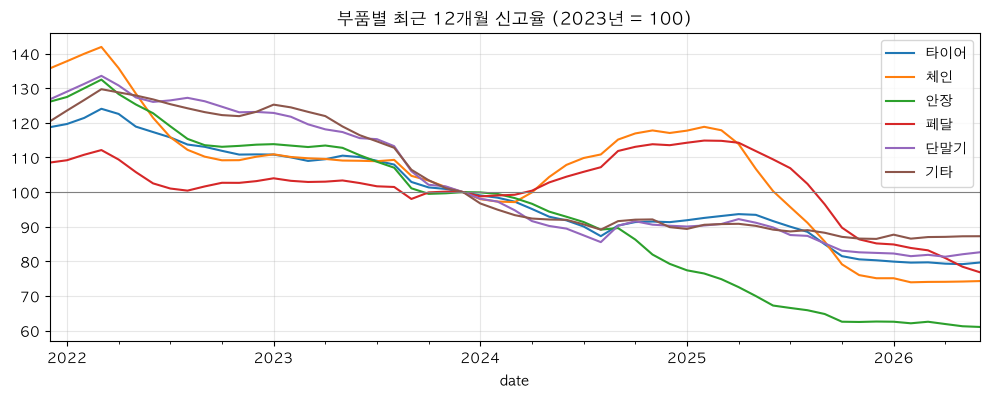

date,2021-12,2022-06,2022-12,2023-06,2023-12,2024-06,2024-12,2025-06,2025-12,2026-06
타이어,119.0,117.0,111.0,110.0,100.0,92.0,91.0,92.0,80.0,80.0
체인,136.0,121.0,110.0,109.0,100.0,108.0,117.0,100.0,75.0,74.0
안장,126.0,123.0,114.0,111.0,100.0,93.0,79.0,67.0,63.0,61.0
페달,109.0,103.0,103.0,103.0,100.0,104.0,114.0,109.0,85.0,77.0
단말기,127.0,126.0,123.0,116.0,100.0,89.0,90.0,90.0,82.0,83.0
기타,120.0,127.0,123.0,116.0,100.0,92.0,90.0,89.0,86.0,87.0


In [8]:
# 부품별 월별 신고율을 한 그림에(최근 12개월 기준, 계절 제거). 2023년 평균을 100으로 맞춰 부품 간 변화 폭을 비교한다
cols = ["fail_tire", "fail_chain", "fail_saddle", "fail_pedal", "fail_terminal", "fail_etc"]
r = mon[cols].rolling(12).sum().div(mon.rentals.rolling(12).sum(), axis=0) * 1e4
idx = (100 * r / r.loc["2023-12"]).rename(columns=PARTS).loc["2021-12":]      # 2023-12 시점 값 = 2023년 1~12월 신고율
ax = idx.plot(figsize=(12, 4), title="부품별 최근 12개월 신고율 (2023년 = 100)")
ax.axhline(100, color="gray", lw=0.8); ax.grid(alpha=0.3)
plt.savefig(ROOT / "output/figures/regime_parts_index.png", dpi=200, bbox_inches="tight"); plt.show()
idx[idx.index.month.isin([6, 12])].round(0).T

## 6. 신고 방식이 바뀐 흔적이 있는가

수준 변화가 '실제 고장'의 변화인지 '신고·집계 방식'의 변화인지 가르는 데 도움이 되는 지표 두 가지.

- **신고 1건당 유형 수**(행 수 ÷ 신고 건수): 신고 화면에서 유형을 고르는 방식이 바뀌면 달라진다
- **'기타' 비중**: 신고 화면의 선택지가 바뀌면 달라진다

(2021-02 ~ 12는 신고에 시각이 없어 같은 날 같은 자전거의 신고가 1건으로 묶인다 → 그 기간의 '신고 1건당 유형 수'는 실제보다 높게 나온다.)

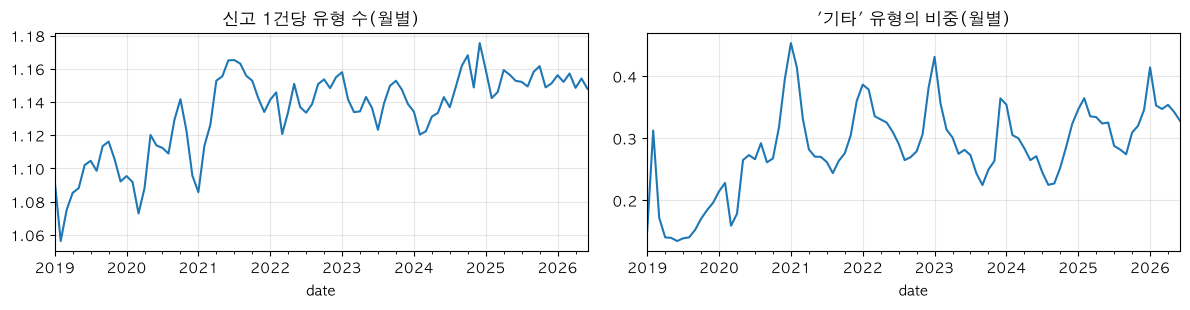

date,2019,2020,2021,2022,2023,2024,2025,2026
types_per_report,1.094,1.108,1.143,1.143,1.142,1.144,1.153,1.153
etc_share,0.169,0.260,0.311,0.322,0.298,0.278,0.321,0.357


In [9]:
rows = m.groupby(m.date.dt.to_period("M")).total_rows.sum()          # 월별 행 수(신고×유형) 합계
q = pd.DataFrame({"types_per_report": rows / mon.total_faults, "etc_share": mon.fail_etc / rows})
fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
q.loc["2019":, "types_per_report"].plot(ax=ax[0], title="신고 1건당 유형 수(월별)"); ax[0].grid(alpha=0.3)
q.loc["2019":, "etc_share"].plot(ax=ax[1], title="'기타' 유형의 비중(월별)"); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.savefig(ROOT / "output/figures/regime_report_style.png", dpi=200, bbox_inches="tight"); plt.show()
q.loc["2019":, ["types_per_report", "etc_share"]].groupby(lambda p: p.year).mean().round(3).T

## 7. 자전거 교체 때문인가 — 도입 연도 묶음별 신고율

**가설**: 새 자전거가 대량으로 들어오면 고장이 덜 나므로 전체 신고율이 내려간다. 2020~2021년의 낮은 신고율과 2016~2018년의 낮은 신고율은 그 때문일 수 있다.

**확인 방법**: 전체 평균이 아니라 '같은 해에 들어온 자전거 묶음'별로 신고율을 따로 본다.
- 새 자전거 때문이라면 → 기존 자전거 묶음의 신고율은 그대로이고, 새 묶음이 낮아서 평균만 내려간다(구성 효과)
- 신고 방식 때문이라면 → **같은 자전거 묶음**의 신고율이 어느 날 갑자기 바뀐다

자전거의 도입 시기는 '대여이력에 그 번호가 처음 나타난 해'로 본다(`py/build/bike_month.py`가 만든 자전거별·월별 대여 건수 사용).
주의: 번호만 새로 붙인 기존 자전거가 있었다면 새 자전거로 잡힌다. 이 자료로는 구분할 수 없다.

In [10]:
bm = pd.read_parquet(ROOT / "data/interim/bike_month/bike_month.parquet")              # 자전거별·월별 대여 건수
bm["ym"] = pd.PeriodIndex("20" + bm.ym.str[:2] + "-" + bm.ym.str[2:], freq="M")       # "2104" → 2021-04
first_year = bm.groupby("bike").ym.min().dt.year.rename("first_year")                # 자전거별 도입 연도(처음 대여된 해)
bm = bm.join(first_year, on="bike")

fs = pd.read_parquet(ROOT / "data/processed/fail_std.parquet").drop_duplicates(["bike", "reg_ts"])   # 신고 1건 = 1행
fs = fs.assign(ym=fs.reg_ts.dt.to_period("M")).join(first_year, on="bike").dropna(subset=["first_year"])

print("도입 연도별 자전거 수:", first_year.value_counts().sort_index().to_dict())

# 표 1: 달력 연도(행) × 도입 연도(열)의 대여 만 건당 신고. 대여가 20만 건 미만인 칸은 값이 튀므로 비운다
R = bm.groupby([bm.ym.dt.year.rename("year"), "first_year"]).n.sum().unstack()
F = fs.groupby([fs.ym.dt.year.rename("year"), "first_year"]).size().unstack()
cohort_year = (F / R * 1e4).where(R > 200_000)
cohort_year.to_csv(ROOT / "output/tables/regime_cohort_by_year.csv")
print("달력 연도(행) × 도입 연도(열): 대여 만 건당 신고")
display(cohort_year.round(0))
print("그 해 대여에서 각 묶음이 차지한 비중")
display(R.div(R.sum(axis=1), axis=0).round(2))

도입 연도별 자전거 수: {2015: 1287, 2016: 3680, 2017: 8227, 2018: 6318, 2019: 5341, 2020: 19462, 2021: 11637, 2022: 9234, 2023: 4389, 2024: 2083, 2025: 2601, 2026: 20}
달력 연도(행) × 도입 연도(열): 대여 만 건당 신고


first_year,2015.0,2016.0,2017.0,2018.0,2019.0,2020.0,2021.0,2022.0,2023.0,2024.0,2025.0,2026.0
year,,,,,,,,,,,,
2015,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016,5.0,6.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017,13.0,10.0,11.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018,49.0,30.0,26.0,23.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2019,87.0,42.0,36.0,37.0,41.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020,NaN,53.0,38.0,37.0,54.0,17.0,NaN,NaN,NaN,NaN,NaN,NaN
2021,NaN,NaN,NaN,NaN,NaN,43.0,36.0,NaN,NaN,NaN,NaN,NaN
2022,NaN,NaN,NaN,NaN,NaN,43.0,36.0,32.0,NaN,NaN,NaN,NaN
2023,NaN,NaN,NaN,NaN,NaN,37.0,35.0,32.0,25.0,NaN,NaN,NaN


그 해 대여에서 각 묶음이 차지한 비중


first_year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
year,,,,,,,,,,,,
2015,1.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016,0.36,0.64,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017,0.11,0.40,0.49,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018,0.02,0.11,0.50,0.37,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2019,0.01,0.10,0.33,0.35,0.21,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020,0.00,0.02,0.09,0.11,0.10,0.67,NaN,NaN,NaN,NaN,NaN,NaN
2021,0.00,0.00,0.00,0.00,0.00,0.72,0.28,NaN,NaN,NaN,NaN,NaN
2022,NaN,NaN,NaN,NaN,NaN,0.49,0.31,0.20,NaN,NaN,NaN,NaN
2023,NaN,NaN,NaN,NaN,NaN,0.38,0.23,0.26,0.13,NaN,NaN,NaN


표 읽는 법
- **세로로**(같은 묶음이 해가 지나며): 2020년 도입 묶음은 2020년 17 → 2021년 43. 같은 자전거가 1년 만에 2.5배다.
- **가로로**(같은 해에 묶음끼리): 2023~2024년에는 새 묶음일수록 낮다 → '새 자전거는 덜 신고된다'는 효과는 실제로 있다.
- 2016~2019년: 2016년 도입 묶음이 6 → 10 → 30 → 42로 올랐지만, **갓 들어온** 묶음끼리 비교해도 2017년 11, 2018년 23, 2019년 41이다. 낡아서가 아니라 신고 자체가 늘어난 것이다.

아래 그림은 2020~2021년을 월별로 본 것이다.

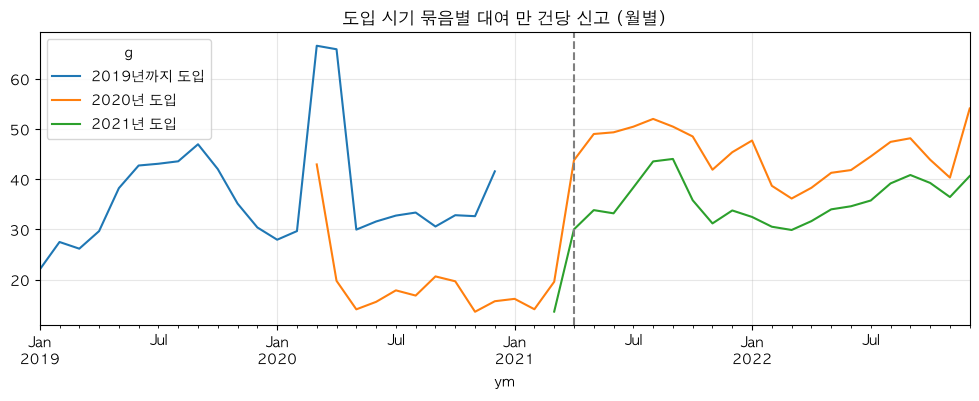

2020년 대여에서 묶음별 비중(월별)


ym,2020-01,2020-02,2020-03,2020-04,2020-05,2020-06,2020-07,2020-08,2020-09,2020-10,2020-11,2020-12,2021-01,2021-02,2021-03,2021-04,2021-05,2021-06
g,,,,,,,,,,,,,,,,,,
2019년까지 도입,1.0,1.0,0.94,0.7,0.43,0.29,0.23,0.13,0.12,0.07,0.04,0.02,0.02,0.01,0.01,0.00,0.00,0.00
2020년 도입,0.0,0.0,0.06,0.3,0.57,0.71,0.77,0.87,0.88,0.93,0.96,0.98,0.98,0.98,0.88,0.78,0.76,0.69
2021년 도입,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00,0.01,0.12,0.22,0.24,0.31


ym,2020-01,2020-02,2020-03,2020-04,2020-05,2020-06,2020-07,2020-08,2020-09,2020-10,2020-11,2020-12,2021-01,2021-02,2021-03,2021-04,2021-05,2021-06,2021-07,2021-08
g,,,,,,,,,,,,,,,,,,,,
2019년까지 도입,28.0,30.0,67.0,66.0,30.0,32.0,33.0,33.0,31.0,33.0,33.0,42.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020년 도입,NaN,NaN,43.0,20.0,14.0,16.0,18.0,17.0,21.0,20.0,14.0,16.0,16.0,14.0,20.0,44.0,49.0,49.0,50.0,52.0
2021년 도입,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,14.0,30.0,34.0,33.0,38.0,44.0


In [11]:
# 그림: 2019년까지 도입분 / 2020년 도입분 / 2021년 도입분의 월별 신고율
grp = lambda y: np.select([y <= 2019, y == 2020, y == 2021], ["2019년까지 도입", "2020년 도입", "2021년 도입"], default="그 뒤")
Rm = bm.assign(g=grp(bm.first_year)).groupby(["ym", "g"]).n.sum().unstack()
Fm = fs.assign(g=grp(fs.first_year)).groupby(["ym", "g"]).size().unstack()
cm = (Fm / Rm * 1e4).where(Rm > 20_000).loc["2019-01":"2022-12", ["2019년까지 도입", "2020년 도입", "2021년 도입"]]   # 월 2만 건 미만은 비움
ax = cm.plot(figsize=(12, 3.8), title="도입 시기 묶음별 대여 만 건당 신고 (월별)")
ax.axvline(pd.Period("2021-04", "M"), color="gray", ls="--"); ax.grid(alpha=0.3)
plt.savefig(ROOT / "output/figures/regime_cohort_monthly.png", dpi=200, bbox_inches="tight"); plt.show()
print("2020년 대여에서 묶음별 비중(월별)")
display(Rm.div(Rm.sum(axis=1), axis=0).loc["2020-01":"2021-06", ["2019년까지 도입", "2020년 도입", "2021년 도입"]].round(2).T)
cm.loc["2020-01":"2021-08"].round(0).T

## 판정 (체크포인트 A) — 사람이 정한다

- [ ] 2025 ~ 2026 상반기는 2023 ~ 2024와 같은 레짐인가?
  - 같다 → 구간 나누기(학습 2020~2023 / 검증 2024 / 테스트 2025~)를 그대로 쓴다
  - 다르다 → ① 모든 모형에 수준 적응 변수(최근 4주 신고율)를 넣고 ② 테스트 결과를 2025 상반기·하반기·2026 상반기로 나눠 보고하고 ③ 원인 조사 결과를 한계 절에 쓴다
- [ ] 학습 구간을 어디서 시작할 것인가(2020년, 2021년, 2022년)
- [ ] 결정 로그에 기록

결과 해석과 결정은 `docs/notes/02_EDA_메모.md`에 적는다.